<a href="https://colab.research.google.com/github/Swalha14/SemProject_MLEngine/blob/main/RandomForest_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mathematics Grade Prediction Using Random Forest Regression

**Project Deliverable 3 – Final ML Module**

## 1. Introduction

This notebook documents the development of a machine learning model for Elimisha AI to predict students' final Mathematics grades (G3) using the UCI Student Performance dataset.

The initial model used Ridge Regression. Following a comparison with Linear Regression and Random Forest, Random Forest was selected because it achieved the best predictive performance among the models tested.

The final model uses seven selected input features instead of the original 32 to simplify student input while retaining relevant information.

This notebook covers data preparation, model training, evaluation, explainability and the final prediction logic.

## 2. Previous Model Development and Selection

The initial model developed in Deliverable 2 was Ridge Regression, using all 32 available input features.

Three algorithms were compared using the same training and testing data:

| Model | Test MAE | Test RMSE | Test R² |
|---|---:|---:|---:|
| Ridge Regression | 1.639 | 2.372 | 0.726 |
| Linear Regression | 1.647 | 2.378 | 0.724 |
| Random Forest | 1.214 | 2.009 | 0.803 |

Random Forest achieved the lowest prediction errors and highest R² score. Ridge Regression was also tuned, but its performance remained lower.

Therefore, Random Forest was selected as the final algorithm. The final version will use seven input features instead of 32, and will be evaluated separately.

## 3. Dataset Loading

The UCI Student Performance dataset (`student-mat.csv`) is used to train the model. It contains student information and academic records, with `G3` representing the final Mathematics grade.

We begin by loading the dataset and inspecting its structure.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving student-mat.csv to student-mat (1).csv


In [12]:
# Load the uploaded dataset
df = pd.read_csv("student-mat.csv", sep=";")

# Inspect the dataset
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


#### 3.1 Dataset Overview

The dataset contains 395 student records and 33 columns, including academic grades, demographic information and student-related characteristics.

The target variable, G3, represents the student's final Mathematics grade on a scale of 0 to 20. The remaining columns provide information that can be explored and used as potential input features for prediction.

## 4. Data Understanding

We inspect the dataset to understand its structure, identify the available features, check data types and determine whether any values are missing. This helps guide feature selection and preprocessing.

In [13]:
# Display dataset information
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Check for duplicate records
print("\nDuplicate records:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

## 5. Feature Selection

Correlation analysis showed that previous grades had the strongest relationships with the final Mathematics grade (G3), with G2 recording 0.905 and G1 recording 0.801. Failures also showed a negative relationship of -0.360.

Other factors, including study time and absences, had weaker relationships. However, feature selection was not based on correlation alone. We also considered the relevance of student habits and personal circumstances to academic performance.

Seven features were selected: G1, G2, studytime, failures, absences, activities and romantic. This reduced the original 32 inputs while retaining potentially useful academic and student-related information.

####  Description of Selected Features

The seven selected features represent a combination of academic performance and student-related factors:

- **G1:** First-period Mathematics grade.
- **G2:** Second-period Mathematics grade.
- **Studytime:** Weekly study time, represented by four categories ranging from less than two hours to more than ten hours.
- **Failures:** Number of previous class failures.
- **Absences:** Number of school absences.
- **Activities:** Whether the student participates in extracurricular activities.
- **Romantic:** Whether the student is in a romantic relationship.

These features were selected to provide the model with relevant academic and student-related information while reducing the number of inputs required.

### 5.1 Visualising Feature Relationships

To support feature selection, we visualise the relationships between numerical features and the final Mathematics grade. A correlation heatmap helps identify numerical relationships, while box plots allow us to compare grade distributions across different student groups. Additional visualisations will be used to explore categorical features

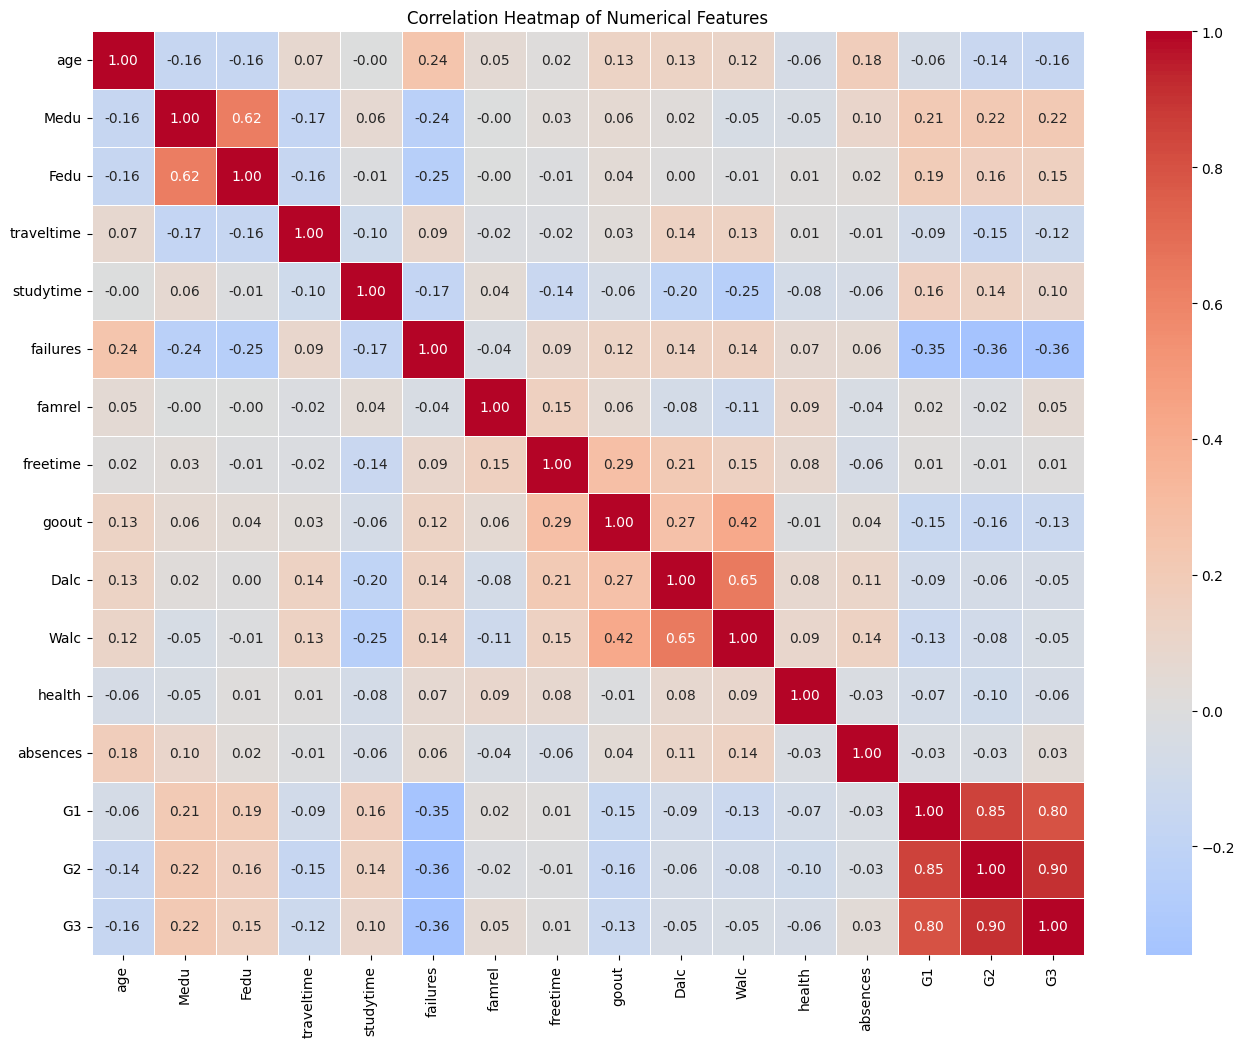

In [17]:
# Select all numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### 5.2 Visualising Categorical Features

We use box plots to examine how final Mathematics grades vary across the categories of student-related features. This allows us to identify differences in grade distributions and explore which categorical features may provide useful information for prediction.

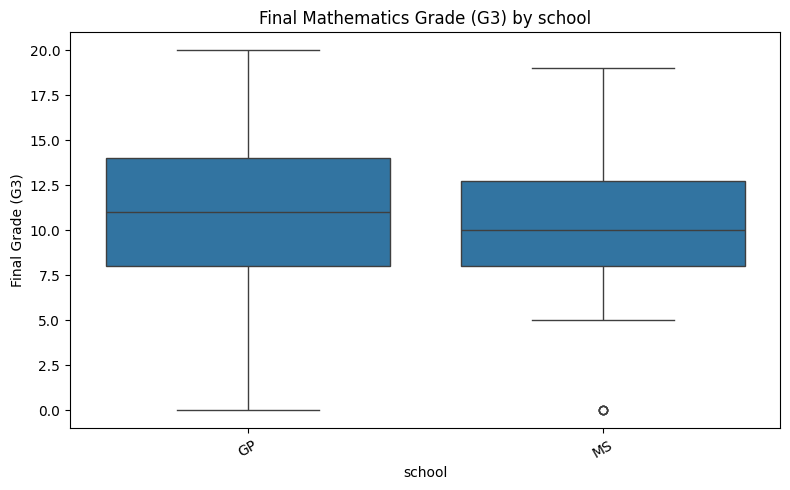

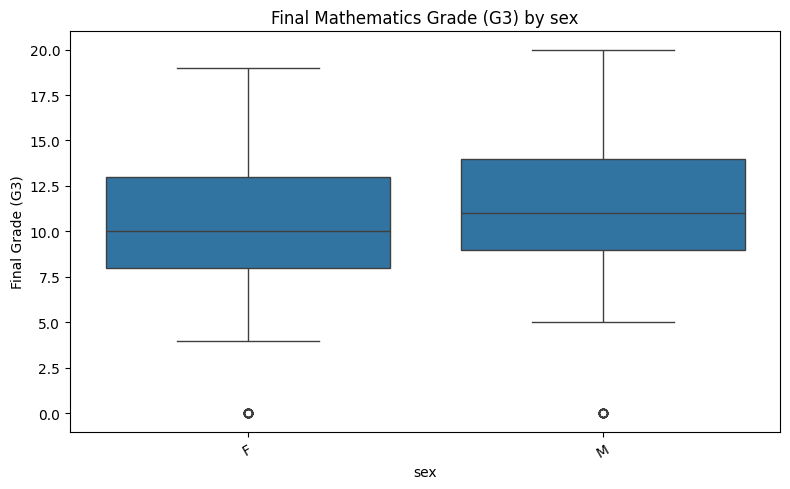

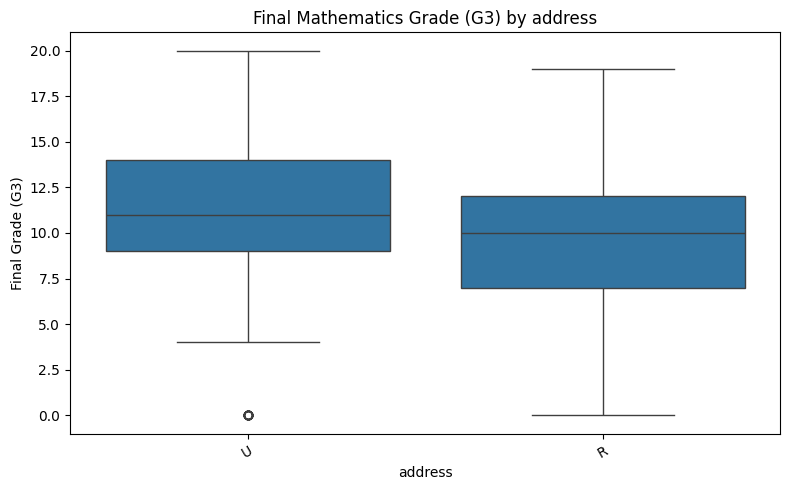

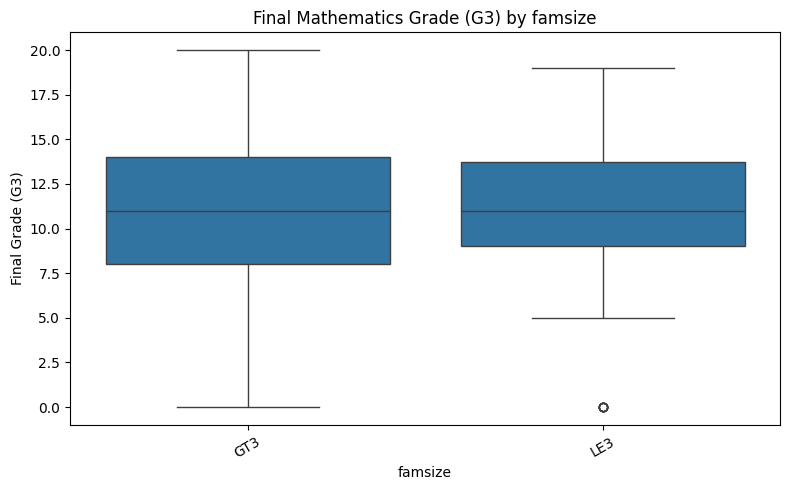

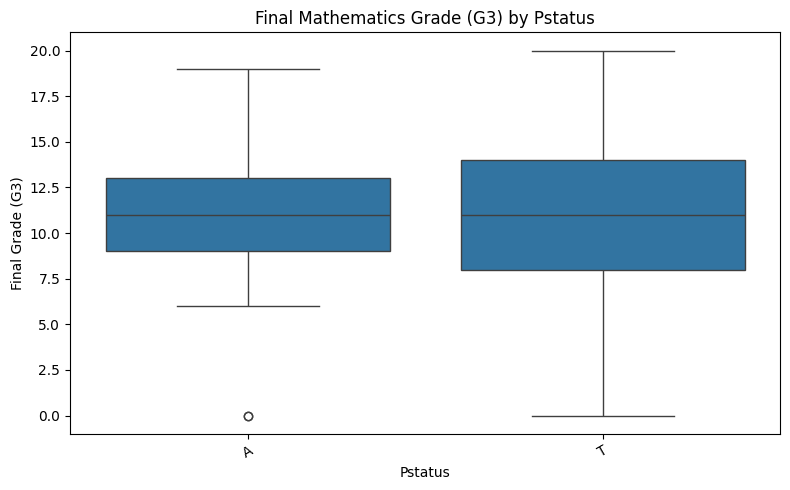

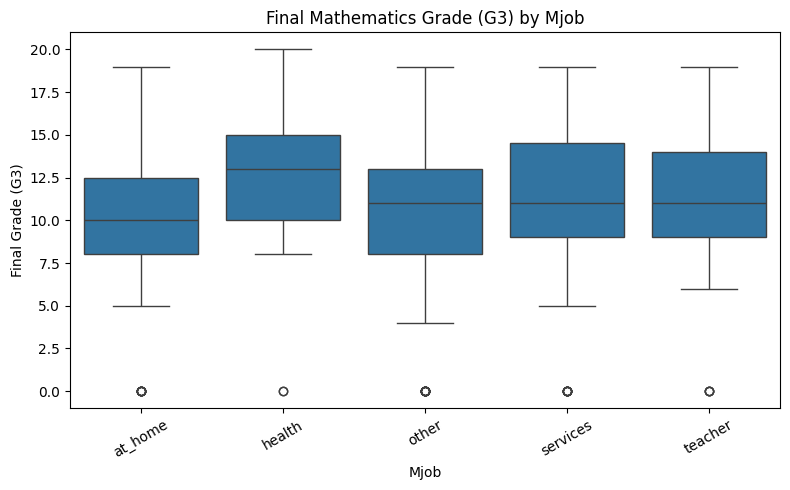

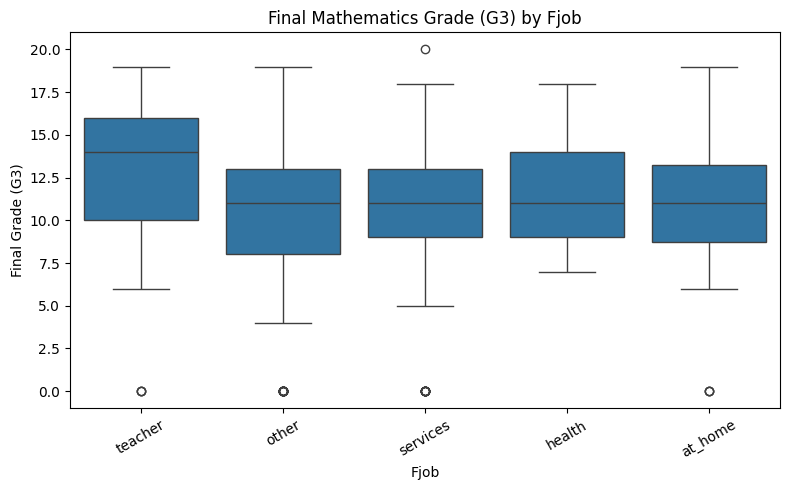

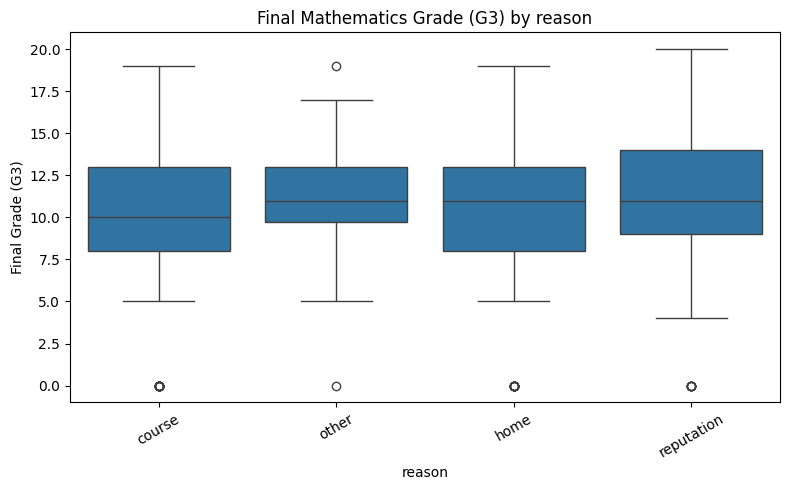

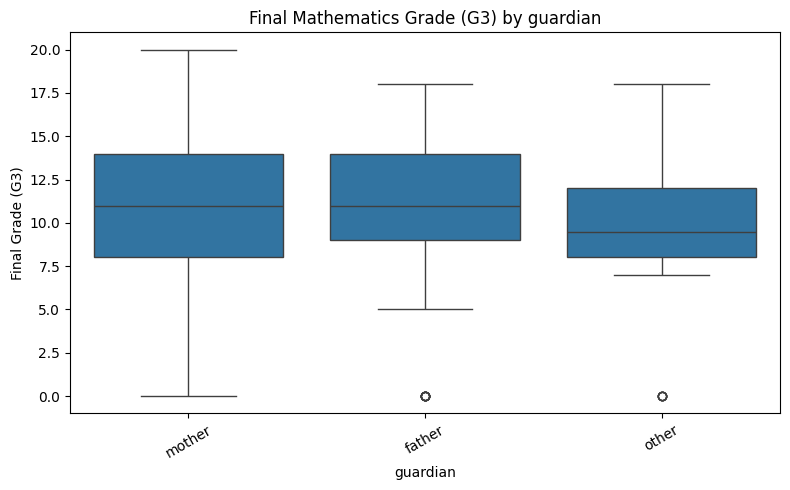

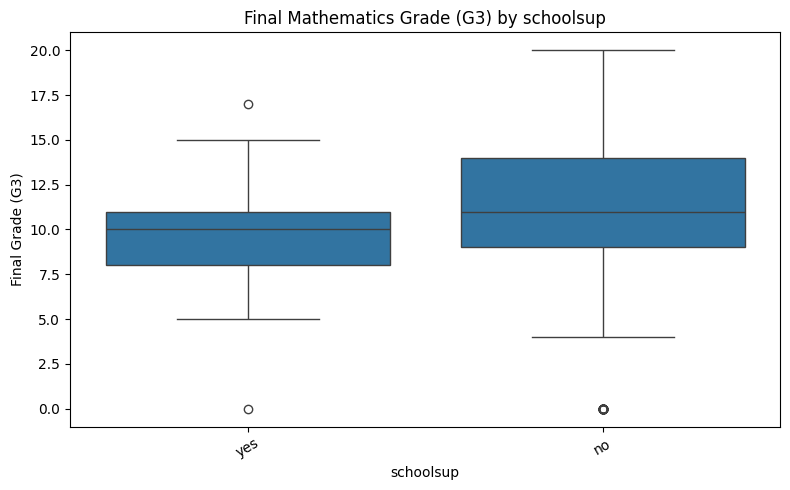

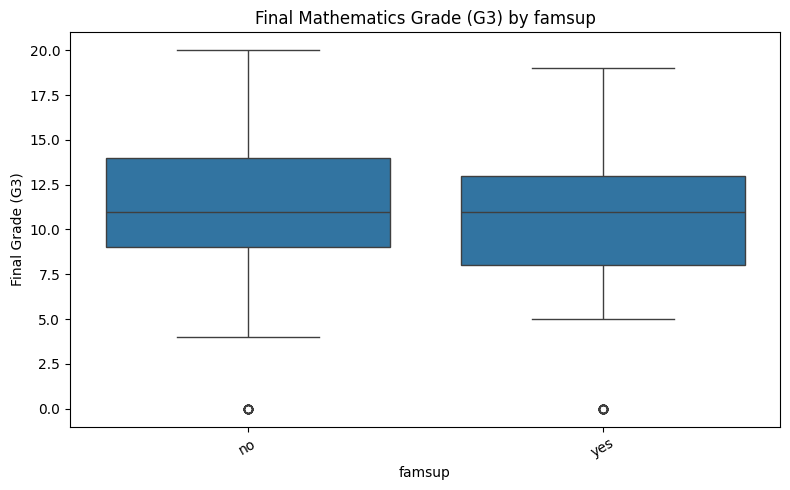

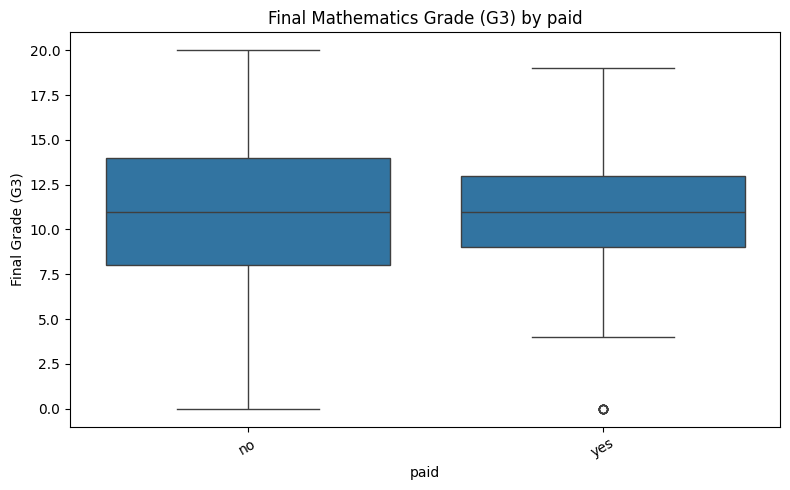

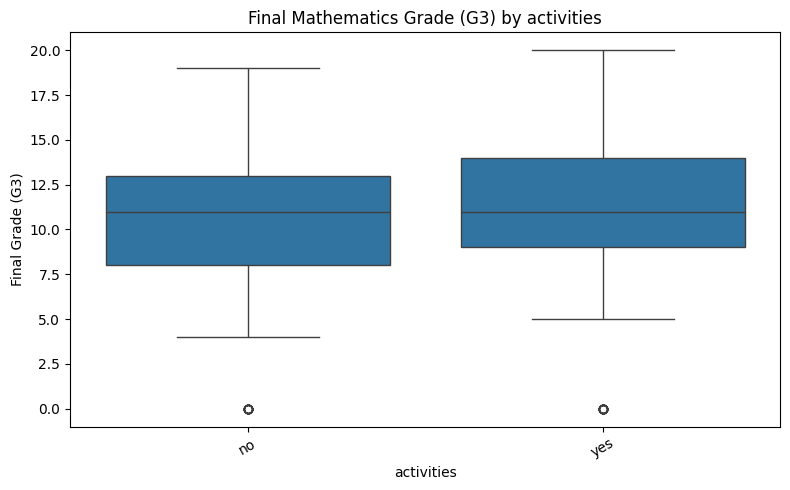

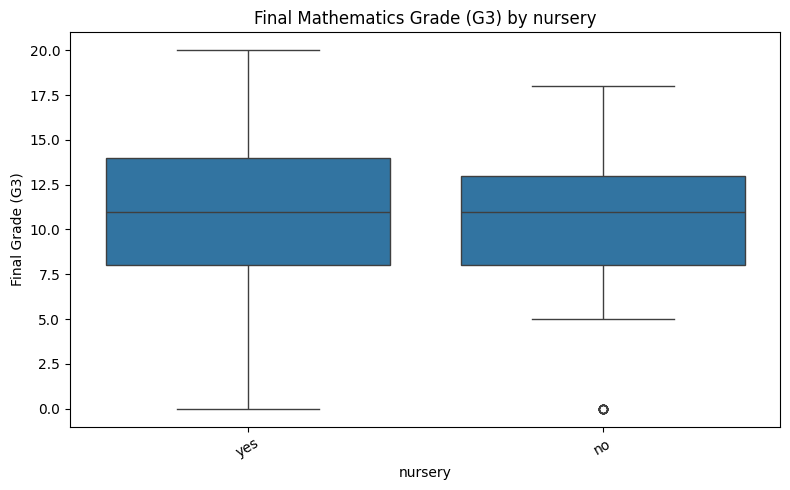

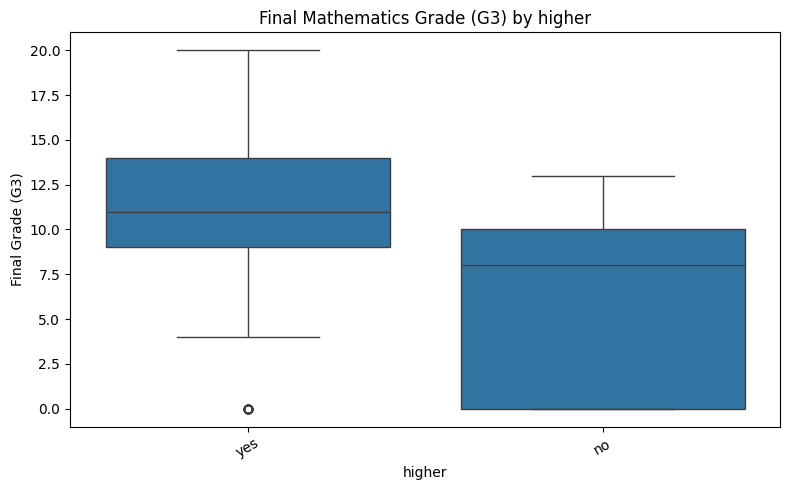

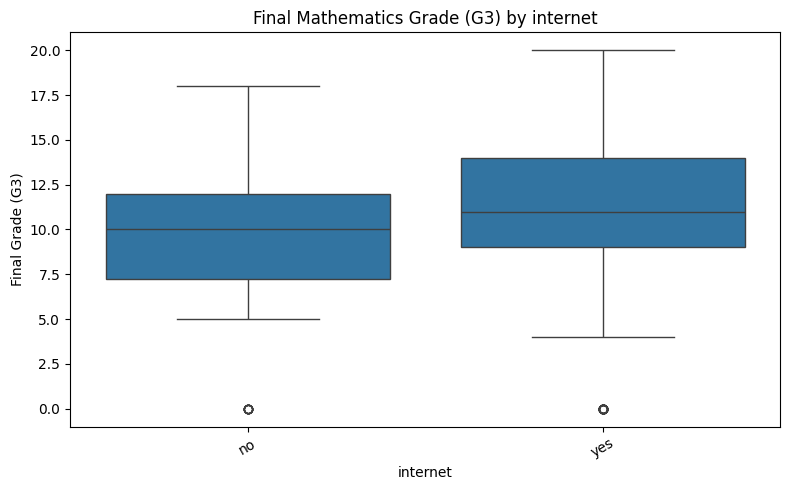

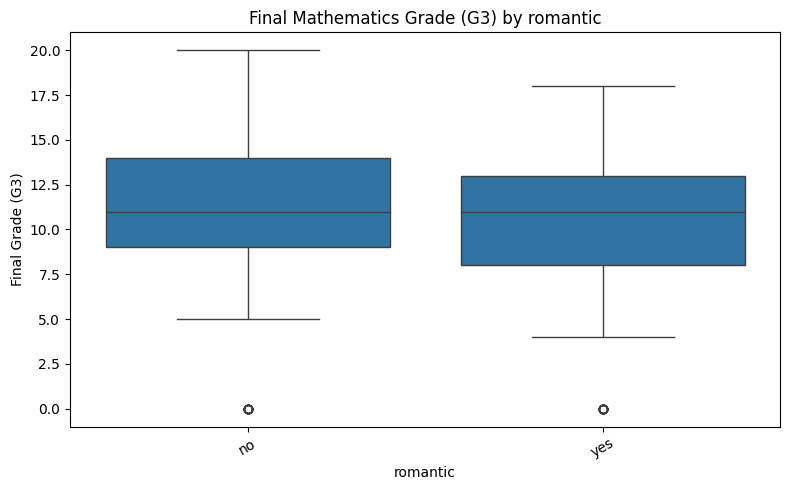

In [18]:
# Identify all categorical columns, excluding the target variable
categorical_features = df.select_dtypes(
    include=["object"]
).columns.tolist()

# Create box plots for all categorical features
for feature in categorical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=feature,
        y="G3"
    )

    plt.title(f"Final Mathematics Grade (G3) by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Final Grade (G3)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

### 5.3 Feature Exploration Observations

The visualisations helped us examine how student characteristics and academic factors relate to final Mathematics grades.

The numerical analysis showed that previous grades (G1 and G2) had the strongest positive relationships with G3, while previous class failures showed a negative relationship.

The categorical box plots allowed us to compare grade distributions across different student groups, including school, family background, academic support and personal characteristics.

These observations informed our selection of seven input features for the final model. The relationships observed do not necessarily imply causation.

## 6. Data Preparation

After exploring the dataset and selecting the relevant features, we prepare the inputs and target variable for model development.

The seven selected features will be used as inputs (`X`), while the final Mathematics grade (`G3`) will be the prediction target (`y`).

In [20]:
# Select the seven input features
selected_features = [
    "G1",
    "G2",
    "studytime",
    "failures",
    "absences",
    "activities",
    "romantic"
]

# Separate input features and target variable
X = df[selected_features]
y = df["G3"]

# Inspect the prepared data
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nInput feature data types:")
print(X.dtypes)

display(X.head())

Input features shape: (395, 7)
Target variable shape: (395,)

Input feature data types:
G1             int64
G2             int64
studytime      int64
failures       int64
absences       int64
activities    object
romantic      object
dtype: object


,G1,G2,studytime,failures,absences,activities,romantic
0,5,6,2,0,6,no,no
1,5,5,2,0,4,no,no
2,7,8,2,3,10,no,no
3,15,14,3,0,2,yes,yes
4,6,10,2,0,4,no,no


## 7. Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. The training data is used to fit the model, while the testing data is reserved for evaluating its predictive performance.

A fixed random state ensures that the split can be reproduced.

In [21]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the resulting dataset sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (316, 7)
Testing features: (79, 7)
Training target: (316,)
Testing target: (79,)


#### 7.1 Train-Test Split Results

The dataset was divided into 316 training records and 79 testing records. The training set is used to teach the model patterns between student information and final grades, while the testing set is used to assess its performance on records that were not used during training.

The 80:20 split provides separate datasets for model development and evaluation.

## 8. Data Preprocessing

The selected features contain both numerical and categorical data. Random Forest can work directly with numerical values, but categorical values must first be converted into numerical representations.

We use One-Hot Encoding for the categorical features. Numerical features are passed through without scaling because Random Forest does not require standardisation unlike our previous Ridge Regression Model.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical features
numerical_features = [
    "G1", "G2", "studytime", "failures", "absences"
]

categorical_features = [
    "activities", "romantic"
]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


#### 8.1 Preprocessing Explanation

One-Hot Encoding converts categorical values into separate numerical columns that the Random Forest model can process.

For example, the activities feature contains the categories "yes" and "no". These are represented as separate binary columns during preprocessing.

The numerical features are passed through unchanged. By combining preprocessing and model training in a pipeline, the same transformations are automatically applied whenever new student information is provided.

## 9. Random Forest Model Development

Random Forest Regression is an ensemble learning algorithm that combines predictions from multiple decision trees to produce a final prediction.

We create a pipeline that combines the preprocessing transformer with the Random Forest model. This ensures that the input data is processed consistently during training and prediction.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest pipeline
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


## 10. Model Training

The Random Forest pipeline is trained using the training dataset. During training, the preprocessing stage transforms the categorical features before the algorithm learns relationships between the input features and final Mathematics grades.


In [24]:
# Train the Random Forest pipeline
rf_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 11. Model Predictions

After training, the model is used to predict final Mathematics grades for the testing dataset. These predictions are compared with the actual grades to evaluate how well the model performs on unseen student records.

In [25]:
# Generate predictions using the testing data
y_pred = rf_pipeline.predict(X_test)

# Compare actual and predicted grades
results = pd.DataFrame({
    "Actual G3": y_test.values,
    "Predicted G3": np.round(y_pred, 2)
})

display(results.head(10))

,Actual G3,Predicted G3
0,10,8.36
1,12,11.63
2,5,6.49
3,10,9.59
4,9,9.47
5,13,13.54
6,18,18.83
7,6,7.13
8,0,7.04
9,14,12.24


## 12. Model Evaluation

Three evaluation metrics were used to assess the model:

Mean Absolute Error (MAE): Measures the average absolute difference between actual and predicted grades. A lower value indicates smaller prediction errors.

Root Mean Squared Error (RMSE): Measures prediction errors while giving greater weight to larger errors. Lower values indicate better performance.

R² Score: Measures how much of the variation in the target variable is explained by the model. A value closer to 1 indicates a better fit to the observed data.

Together, these metrics provide different perspectives on the predictive performance of the Random Forest model.

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Model Performance")
print("--------------------------------")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

Random Forest Model Performance
--------------------------------
MAE:  1.186
RMSE: 1.989
R²:   0.807


### 12.1 Evaluation Results

The seven-feature Random Forest model achieved an MAE of 1.186, RMSE of 1.989 and R² score of 0.807.

This indicates that the model can explain approximately 80.7% of the variation in final Mathematics grades, with an average absolute prediction error of approximately 1.19 points.

Compared with the previous 32-feature Random Forest model, the final model achieved slightly better results while requiring fewer student inputs.

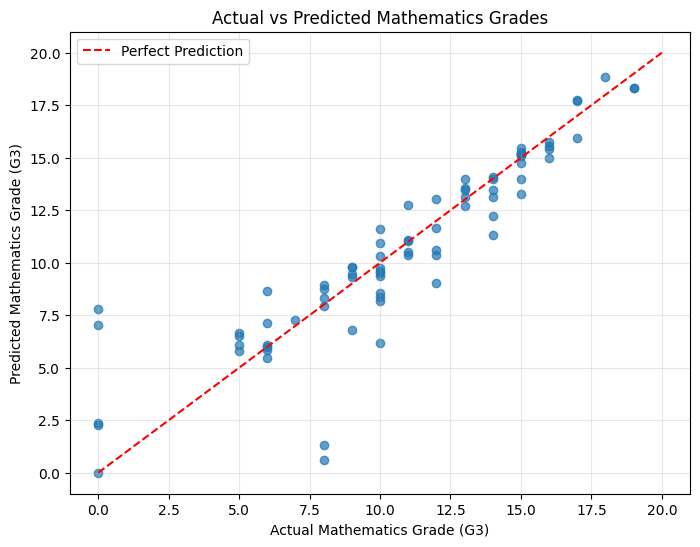

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot([0, 20], [0, 20], "r--", label="Perfect Prediction")

plt.xlabel("Actual Mathematics Grade (G3)")
plt.ylabel("Predicted Mathematics Grade (G3)")
plt.title("Actual vs Predicted Mathematics Grades")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 13. Cross-Validation

We use 5-fold cross-validation to evaluate the consistency of the Random Forest model.

The training data is divided into five subsets. The model is trained and evaluated five times, using a different subset for validation each time. The average score provides a broader assessment of model performance.

In [28]:
from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation on the training data
cv_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:", np.round(cv_scores, 3))
print("Mean CV R²:", round(cv_scores.mean(), 3))
print("Standard deviation:", round(cv_scores.std(), 3))

Cross-validation R² scores: [0.912 0.895 0.908 0.909 0.845]
Mean CV R²: 0.894
Standard deviation: 0.025


### 13.1 Cross-Validation Results

The five-fold cross-validation produced a mean R² score of 0.894 and a standard deviation of 0.025.

The relatively low standard deviation indicates that the model maintained consistent performance across the five validation folds. The held-out test set provides a separate assessment of the model's performance on unseen records, with an R² score of 0.807.

Together, these results provide additional insight into the model's performance and consistency.

### 14. Model Explainability – Feature Importance

Feature importance helps us understand which input features the Random Forest model relies on most when making predictions. The model assigns an importance score to each feature based on its contribution to the decision-making process.

Since categorical features are converted into multiple encoded columns during preprocessing, their importance scores are combined to represent the original seven input features.

In [29]:
# Get the transformed feature names and importance scores
feature_names = rf_pipeline.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Encoded Feature": feature_names,
    "Importance": importances
})

# Combine encoded categories into their original features
importance_df["Feature"] = importance_df["Encoded Feature"].str.replace(
    "categorical__", "", regex=False
).str.replace(
    "numerical__", "", regex=False
).str.replace(
    r"_(no|yes)$", "", regex=True
)

feature_importance = (
    importance_df.groupby("Feature", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
)

display(feature_importance)

,Feature,Importance
1,G2,0.801169
2,absences,0.116953
0,G1,0.027241
5,romantic,0.018544
3,activities,0.016759
6,studytime,0.011121
4,failures,0.008212


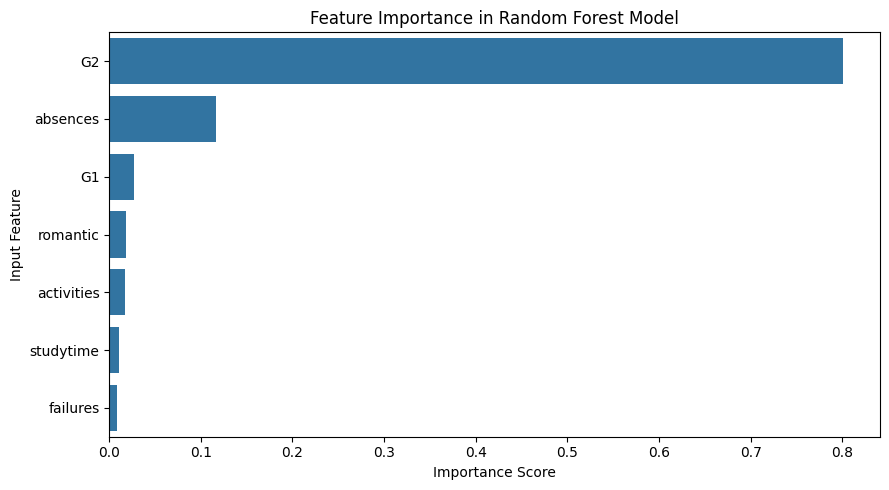

In [49]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Random Forest Model")
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.tight_layout()
plt.show()

#### 14.1 Interpretation of Feature Importance

The feature-importance analysis shows that G2 (second-period grade) is the most influential feature, with an importance score of approximately 0.801. Absences follows with approximately 0.117. The remaining features have considerably smaller importance scores.

These results indicate that the model relies primarily on students' previous academic performance, particularly their second-period grade, when predicting their final Mathematics grade. Absences also contributes to the model's predictions.

Feature importance explains the model's relative reliance on different inputs; it does not establish causal relationships.

### 15. Prediction Function

A prediction function allows the trained Random Forest model to receive new student information and generate a predicted final Mathematics grade.

The function accepts the seven selected input features, arranges them into the format expected by the trained pipeline, and returns the predicted grade.

In [30]:
def predict_student_grade(G1, G2, studytime, failures, absences, activities, romantic):

    # Arrange the student information into a DataFrame
    student_data = pd.DataFrame([{
        "G1": G1,
        "G2": G2,
        "studytime": studytime,
        "failures": failures,
        "absences": absences,
        "activities": activities,
        "romantic": romantic
    }])

    # Generate the predicted final grade
    prediction = rf_pipeline.predict(student_data)

    # Return the predicted grade rounded to two decimal places
    return round(float(prediction[0]), 2)


print("Prediction function created successfully.")

Prediction function created successfully.


In [31]:
predicted_grade = predict_student_grade(
    G1=12,
    G2=14,
    studytime=2,
    failures=0,
    absences=3,
    activities="yes",
    romantic="no"
)

print("Predicted Final Mathematics Grade:", predicted_grade)

Predicted Final Mathematics Grade: 14.15


#### 15.1 Testing the Prediction Function

The prediction function was tested using sample student information to verify that the trained Random Forest model can generate predictions for new student records.

The test provided the inputs as shown in the cell above.

The function passed these values to the trained Random Forest pipeline, which automatically performed the required preprocessing before generating a prediction.

The model returned a predicted final Mathematics grade (G3) of **14.15 out of 20**.

This test confirms that the prediction function successfully accepts student information, processes the inputs and returns a predicted grade. It demonstrates how the trained model can be used to generate predictions for individual student records.

### 16. Input Validation

Input validation ensures that the information provided to the prediction function follows the expected format and valid ranges. This prevents invalid student records from being passed to the model.

In [32]:
def validate_student_input(G1, G2, studytime, failures, absences, activities, romantic):

    if not isinstance(G1, (int, np.integer)) or not 0 <= G1 <= 20:
        raise ValueError("G1 must be a whole number between 0 and 20.")

    if not isinstance(G2, (int, np.integer)) or not 0 <= G2 <= 20:
        raise ValueError("G2 must be a whole number between 0 and 20.")

    if not isinstance(studytime, (int, np.integer)) or studytime not in [1, 2, 3, 4]:
        raise ValueError("Studytime must be a whole number between 1 and 4.")

    if not isinstance(failures, (int, np.integer)) or failures < 0:
        raise ValueError("Failures must be a non-negative whole number.")

    if not isinstance(absences, (int, np.integer)) or absences < 0:
        raise ValueError("Absences must be a non-negative whole number.")

    if activities not in ["yes", "no"]:
        raise ValueError("Activities must be 'yes' or 'no'.")

    if romantic not in ["yes", "no"]:
        raise ValueError("Romantic must be 'yes' or 'no'.")

    return True


print("Input validation function created successfully.")

Input validation function created successfully.


#### 16.1 Testing Input Validation

The input validation function was tested using both valid and invalid student information. This ensures that the system accepts inputs within the expected ranges and rejects values that do not meet the requirements.

In [33]:
validate_student_input(
    G1=12,
    G2=14,
    studytime=2,
    failures=0,
    absences=3,
    activities="yes",
    romantic="no"
)

print("Valid student input accepted.")

Valid student input accepted.


In [34]:
try:
    validate_student_input(
        G1=25,
        G2=14,
        studytime=2,
        failures=0,
        absences=3,
        activities="yes",
        romantic="no"
    )
except ValueError as error:
    print("Invalid input rejected:", error)

Invalid input rejected: G1 must be a whole number between 0 and 20.


#### 16.2 Validation Test Results

The validation tests confirmed that the function correctly handles valid and invalid student information.

The valid input test was accepted successfully, while the invalid input test was rejected because the first-period grade (G1) was 25, exceeding the permitted range of 0–20.

This demonstrates that input validation helps prevent incorrect student information from being passed to the prediction model.

### 17. Integrating Input Validation

The input validation function is integrated into the prediction function to ensure that student information is checked before being passed to the trained Random Forest model.

If the provided information is invalid, the function raises an error and stops the prediction process. Otherwise, the information is processed by the trained pipeline to generate the predicted final Mathematics grade.

In [35]:
def predict_student_grade(G1, G2, studytime, failures, absences, activities, romantic):

    # Validate the student information
    validate_student_input(G1, G2, studytime, failures, absences, activities, romantic)

    # Arrange the student information into a DataFrame
    student_data = pd.DataFrame([{
        "G1": G1,
        "G2": G2,
        "studytime": studytime,
        "failures": failures,
        "absences": absences,
        "activities": activities,
        "romantic": romantic
    }])

    # Generate the predicted final grade
    prediction = rf_pipeline.predict(student_data)

    return round(float(prediction[0]), 2)


print("Validated prediction function created successfully.")

Validated prediction function created successfully.


In [36]:
predicted_grade = predict_student_grade(
    G1=12,
    G2=14,
    studytime=2,
    failures=0,
    absences=3,
    activities="yes",
    romantic="no"
)

print("Predicted Final Mathematics Grade:", predicted_grade)

Predicted Final Mathematics Grade: 14.15


### 18. Testing the Integrated Prediction Function

The updated prediction function was tested with invalid student information to verify that input validation occurs before the model generates a prediction.

In [37]:
try:
    predict_student_grade(
        G1=25,
        G2=14,
        studytime=2,
        failures=0,
        absences=3,
        activities="yes",
        romantic="no"
    )
except ValueError as error:
    print("Prediction stopped:", error)

Prediction stopped: G1 must be a whole number between 0 and 20.


### 19. Testing Different Student Profiles

The prediction function was tested using different student profiles to observe how variations in academic performance and student-related information affect the predicted final Mathematics grade.

This demonstrates that the model generates individual predictions based on the information provided.

In [38]:
student_profiles = [
    {
        "Student": "Profile 1",
        "G1": 15, "G2": 17, "studytime": 3,
        "failures": 0, "absences": 2,
        "activities": "yes", "romantic": "no"
    },
    {
        "Student": "Profile 2",
        "G1": 8, "G2": 9, "studytime": 1,
        "failures": 1, "absences": 10,
        "activities": "no", "romantic": "yes"
    },
    {
        "Student": "Profile 3",
        "G1": 12, "G2": 14, "studytime": 2,
        "failures": 0, "absences": 3,
        "activities": "yes", "romantic": "no"
    }
]

profile_results = []

for profile in student_profiles:
    inputs = {key: value for key, value in profile.items() if key != "Student"}

    predicted_grade = predict_student_grade(**inputs)

    profile_results.append({
        "Student": profile["Student"],
        "G1": profile["G1"],
        "G2": profile["G2"],
        "Predicted G3": predicted_grade
    })

profile_results_df = pd.DataFrame(profile_results)
display(profile_results_df)

,Student,G1,G2,Predicted G3
0,Profile 1,15,17,17.91
1,Profile 2,8,9,9.27
2,Profile 3,12,14,14.15


#### 19.1 Interpretation of Student Profile Predictions

The model was tested using three different student profiles, producing predicted final Mathematics grades of 17.91, 9.27 and 14.15.

Profile 1 received the highest prediction, while Profile 2 received the lowest. Profile 3 received a prediction between the two.

The differences demonstrate that the model responds to variations in the student information provided. Since multiple input features differ between the profiles, the changes in predictions reflect their combined influence on the model.

These predictions are estimates and should not be interpreted as guaranteed final grades.

### 20. Saving the Trained Model

After training and evaluating the Random Forest model, the trained pipeline is saved for future use. This allows the mobile application to load the model and generate predictions without repeating the training process.

The saved pipeline includes both the preprocessing steps and the trained Random Forest model.

In [39]:
import joblib

joblib.dump(rf_pipeline, "random_forest_grade_model.joblib")

print("Trained model saved successfully.")

Trained model saved successfully.


In [40]:
from google.colab import files

files.download("random_forest_grade_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 21. Testing the Saved Model

The saved model is loaded back into the notebook to verify that it can be reused successfully. This ensures that the trained pipeline can generate predictions without requiring the model to be trained again.

In [41]:
loaded_model = joblib.load("random_forest_grade_model.joblib")

print("Saved model loaded successfully.")

Saved model loaded successfully.


In [48]:
student_data = pd.DataFrame([{
    "G1": 12,
    "G2": 14,
    "studytime": 2,
    "failures": 0,
    "absences": 3,
    "activities": "yes",
    "romantic": "no"
}])

loaded_prediction = loaded_model.predict(student_data)

print("Prediction from saved model:", round(float(loaded_prediction[0]), 2))

Prediction from saved model: 14.15


#### 21.1 Saved Model Verification

The saved Random Forest pipeline was successfully loaded and tested using the same sample student information used earlier.

The loaded model generated a predicted final Mathematics grade of 14.15, matching the prediction from the original trained pipeline.

This confirms that the saved model retains its preprocessing and prediction capabilities and can be reused without repeating the training process.

# 22. Final Model Summary

The final machine learning model developed for Elimisha AI is a Random Forest Regression model trained to predict students' final Mathematics grades (G3).

The model uses seven selected input features:

1. First-period grade (G1)
2. Second-period grade (G2)
3. Study time
4. Previous class failures
5. Number of absences
6. Participation in extracurricular activities
7. Romantic relationship status

The final model achieved the following evaluation results:

- **Mean Absolute Error (MAE):** 1.186
- **Root Mean Squared Error (RMSE):** 1.989
- **R² Score:** 0.807
- **Mean Cross-Validation R²:** 0.894

Feature-importance analysis identified G2 as the most influential feature, followed by absences.

The prediction function accepts student information, validates the inputs and generates an estimated final Mathematics grade. The trained preprocessing pipeline and Random Forest model were also saved and successfully loaded for testing.

The final model will serve as the machine learning component of Elimisha AI, providing performance predictions that can support personalised learning recommendations within the mobile application.